Python DA Assignment 2 - Data Visualization

1) Loading the Taxis Dataset

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


2) Handling Missing Values


➢ Check for missing values in the dataset and identify columns with missing data.


In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")



df.isnull()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6429,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6430,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6431,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


➢ Impute missing values using appropriate strategies based on the column type (e.g.,
using mean, median, or mode for numerical columns, and mode for categorical
columns).

In [ ]:
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])

df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])

df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])

df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


➢ For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.

In [ ]:
df = df.dropna()

3) Visualizations using Matplotlib/Pandas Plot:


★ Line Chart
Plot a line chart to visualize the fare over time, using the pickup timestamp as the
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
format before plotting.

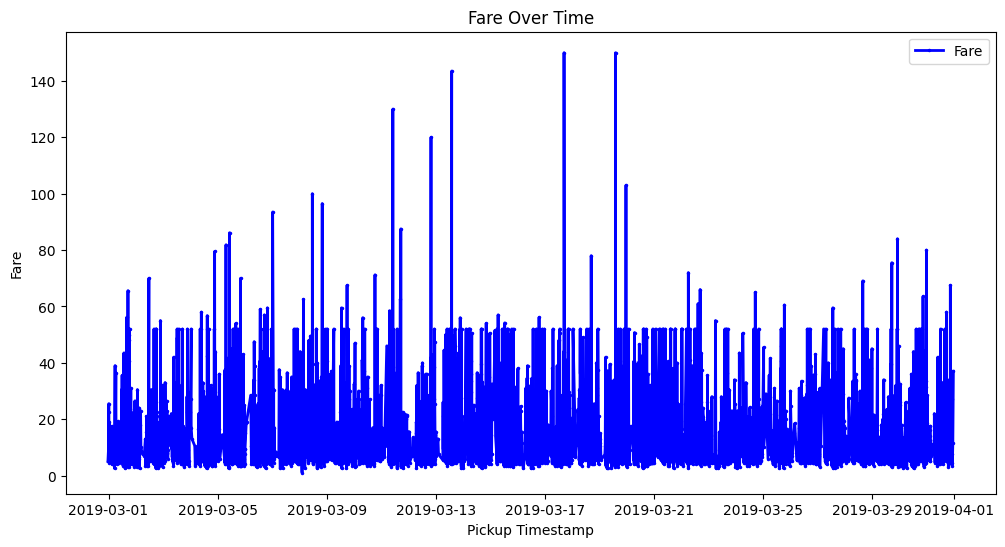

In [ ]:


# Line Graph
df['pickup'] = pd.to_datetime(df['pickup'])
df = df.sort_values('pickup')

x = df['pickup']
y = df['fare']

plt.figure(figsize=(12, 6), dpi=100)

plt.plot(x, y, label='Fare', color='blue', linewidth=2, linestyle='-', marker='.', markersize=3)

plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')

plt.legend()
plt.show()

★ Bar Chart

Create a bar chart to show the total fare for each pickup_borough. Group the data
by pickup_borough and sum the fare for each group.

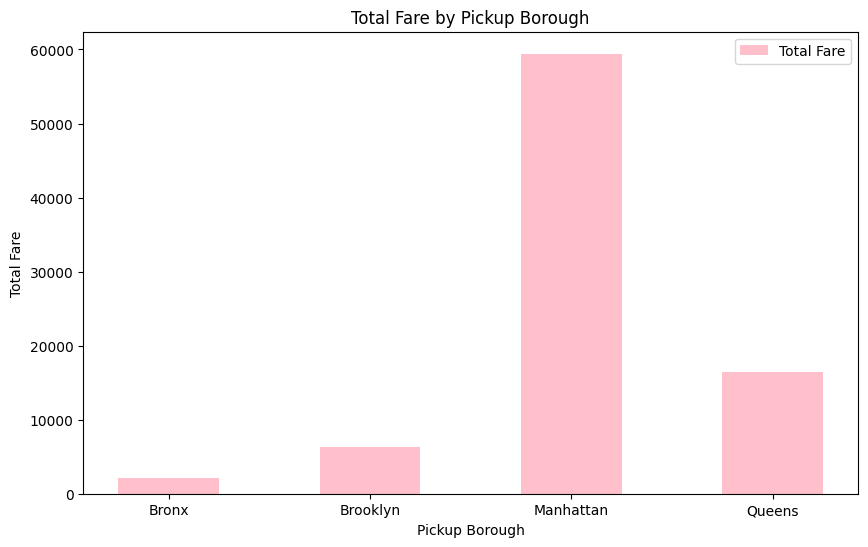

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Bar Graph
borough_fare = df.groupby('pickup_borough')['fare'].sum()

x = borough_fare.index
y = borough_fare.values

plt.figure(figsize=(10, 6), dpi=100)

plt.bar(x, y, color='pink', label='Total Fare', width=0.5)

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.legend()
plt.show()

★ Pie Chart

Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

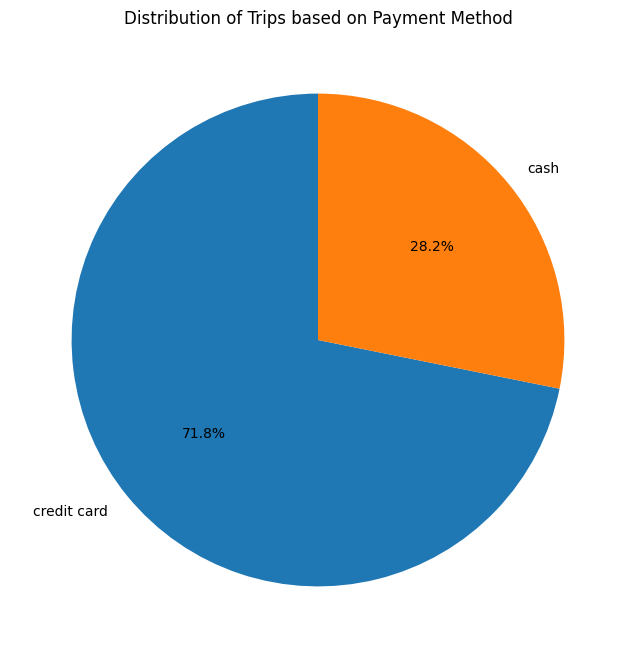

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Pie Chart
payment_count = df['payment'].value_counts()

x = payment_count.index
y = payment_count.values

plt.figure(figsize=(8, 8), dpi=100)

plt.pie(y, labels=x, autopct='%1.1f%%',
        startangle=90, shadow=False)

plt.title('Distribution of Trips based on Payment Method')

plt.show()

★ Histogram

Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

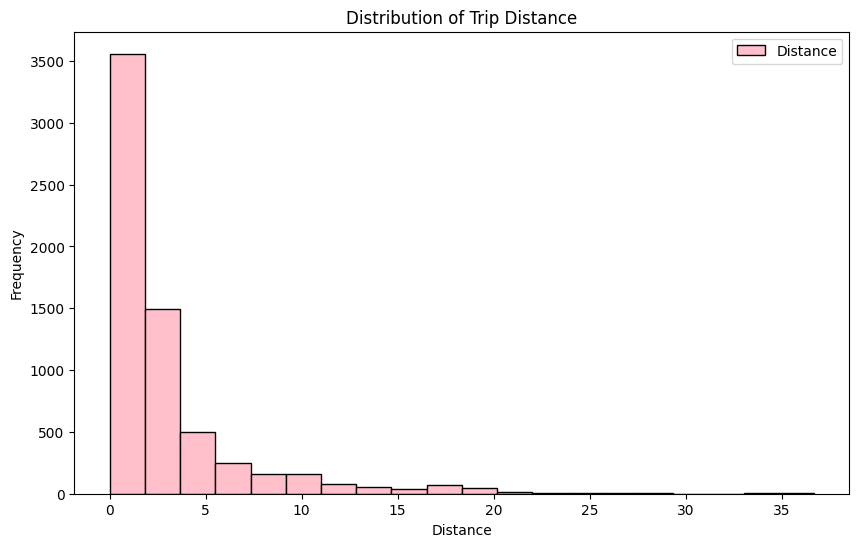

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Histogram
x = df['distance'].dropna()

plt.figure(figsize=(10, 6), dpi=100)

plt.hist(x, bins=20, color='pink',
         edgecolor='black', label='Distance')

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.legend()
plt.show()

★ Box Plot

Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

<Figure size 1000x600 with 0 Axes>

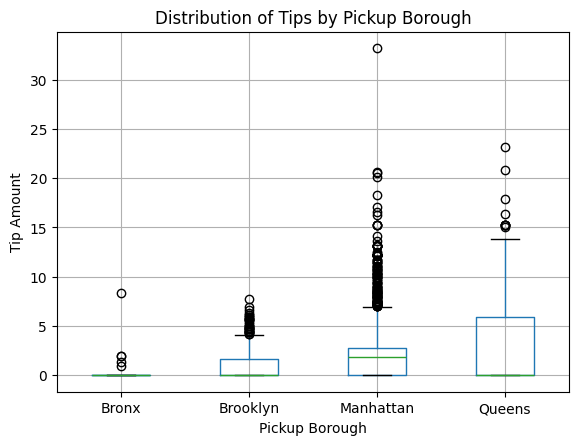

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Box Plot
x = df['pickup_borough']
y = df['tip']

plt.figure(figsize=(10, 6), dpi=100)

df.boxplot(column='tip', by='pickup_borough')

plt.title('Distribution of Tips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.suptitle('')
plt.show()

Visualizations using Seaborn:


★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

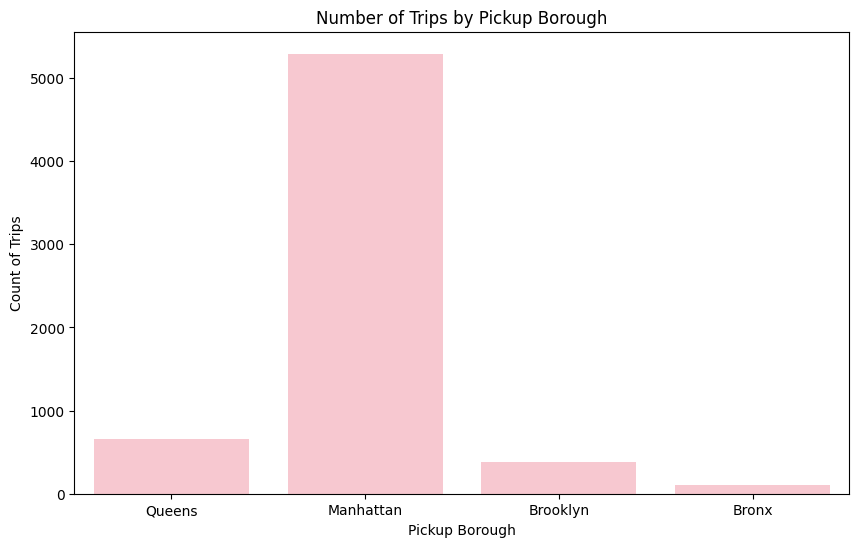

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Count Plot
plt.figure(figsize=(10, 6), dpi=100)

sns.countplot(data=df, x='pickup_borough', color='pink')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count of Trips')

plt.show()

★ Scatter Plot

Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

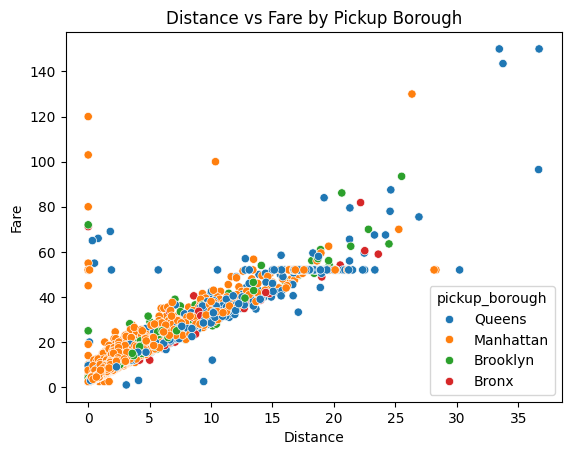

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough')

plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.show()

★ Heatmap

Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

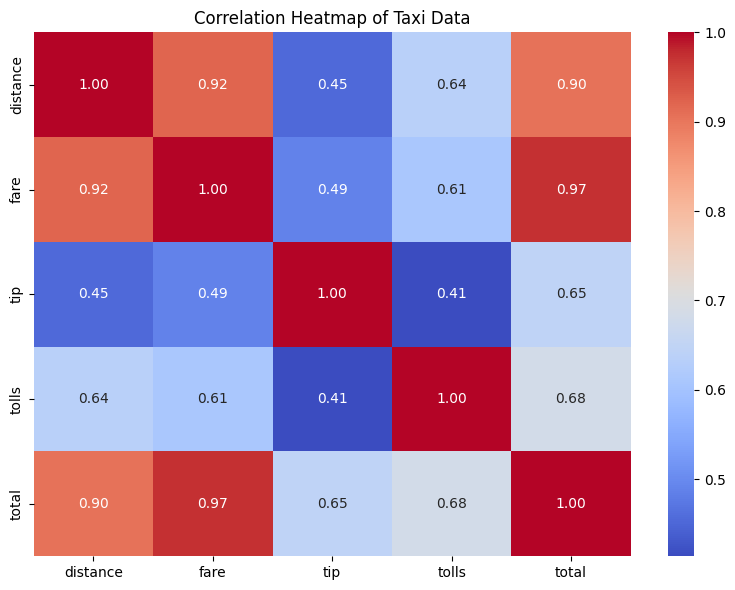

In [ ]:
data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

plt.figure(figsize=(8, 6))

sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Taxi Data')
plt.tight_layout()
plt.show()

★ Pair Plot

Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.

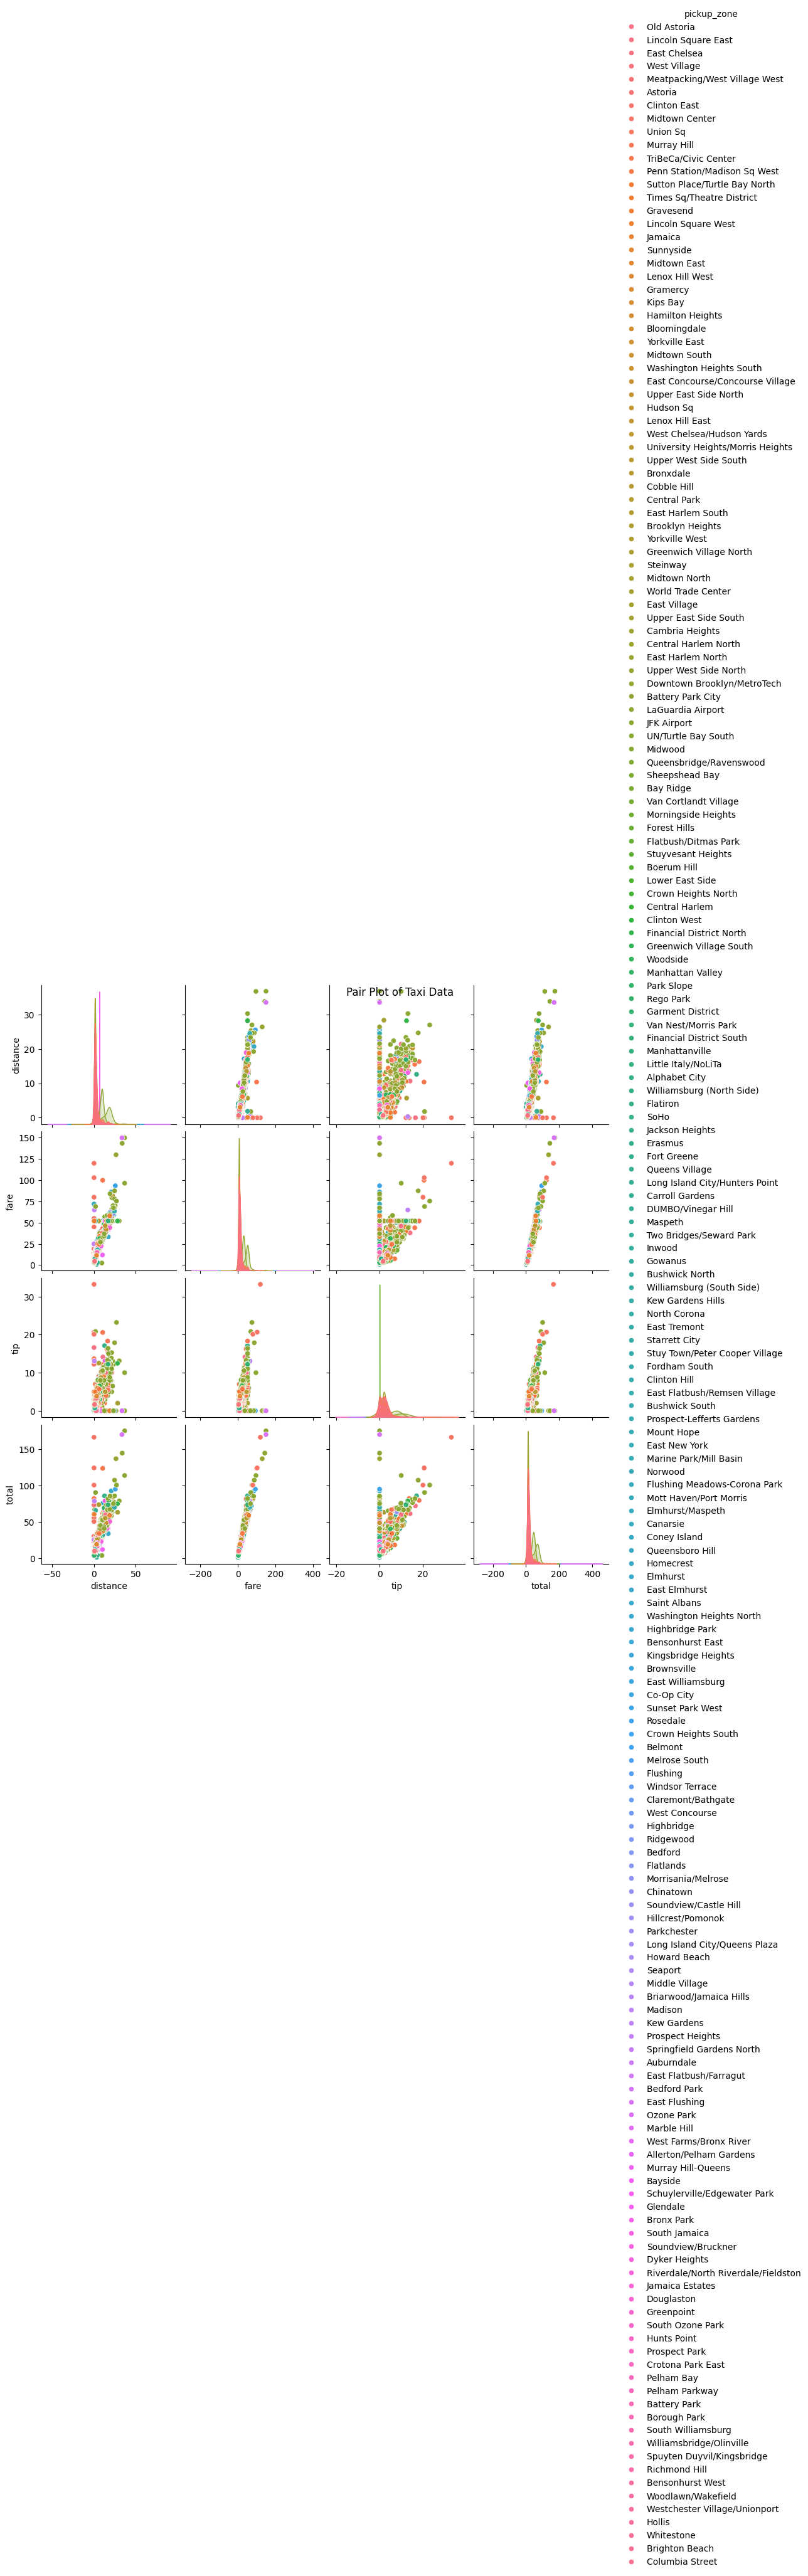

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, vars=['distance', 'fare', 'tip', 'total'], hue='pickup_zone')

plt.suptitle('Pair Plot of Taxi Data')

plt.show()

★ Violin Plot

Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

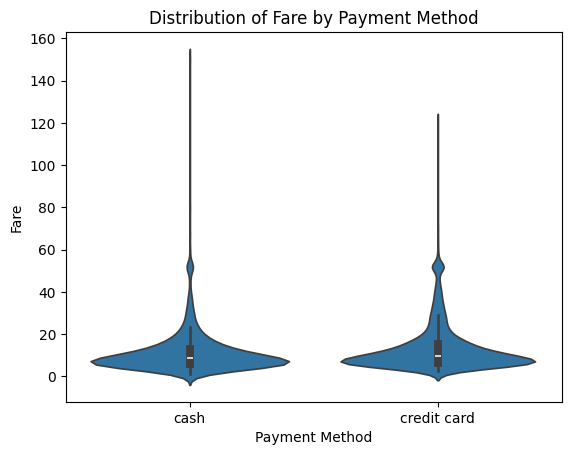

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.violinplot(x='payment', y='fare', data=df)

plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.show()